# CSE 366: Artificial Intelligence / Machine Learning Project
## Submission 4: Custom CNN with an Attention Module (CBAM)
**Group 3 · Department of CSE, East West University**
**Domain:** Precision agriculture and computer vision for foliar disease diagnosis
**Dataset:** PlantVillage (Kaggle `emmarex/plantdisease`), the same 15-class subset as Submission 1: Pepper (2 classes), Potato (3) and Tomato (10), 20,638 RGB leaf images

### Experiment design (roadmap, Submission 4)
The custom CNN from Submission 3 is taken as the **baseline**. Exactly **one attention module (CBAM)** is added after the last convolutional block. **Nothing else changes**: same architecture otherwise, same split, same augmentation, same loss, same optimiser, learning-rate schedule, early-stopping rule and random seed. The notebook checks that all other layers start from identical weights, and that the batch order and augmentation are identical, so any difference comes from the attention module.

| Requirement | Where |
|---|---|
| Add one attention module (CBAM, SE, self-attention or GCNet) | CBAM, Section 5 |
| Full metrics as in Submissions 2 and 3 | Section 6 |
| Baseline vs attention comparison | Section 7: metrics, per-class change, paired significance test, three-seed study, attention maps |

---
## 1. Environment and configuration
Every submission uses the same configuration, the same random seed and the same stratified 70/15/15 split, so results are comparable across notebooks.

> **Compute note.** This notebook was executed on a CPU-only machine (2 cores, no GPU). To keep the full protocol feasible there, images are resized to **64 × 64** instead of the usual 224 × 224. The only thing to change for a higher-resolution run on a GPU (for example Google Colab) is `IMG_SIZE` in the cell below; the image cache is rebuilt automatically.

In [1]:
# ---- Imports, configuration and reproducibility (identical in every submission) ----
import os, sys, time, json, copy, math, random, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as tvm
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except Exception:                       # plain-python fallback
    display = lambda obj: print(obj.to_string() if hasattr(obj, "to_string") else obj)

# ------------------------- Global configuration -------------------------
SEED       = 42        # seed for the data split and for training
IMG_SIZE   = 64        # input resolution (64 keeps CPU training feasible; use 128 or 224 on a GPU)
BATCH_SIZE = 64
VAL_FRAC   = 0.15      # stratified 70 / 15 / 15 split
TEST_FRAC  = 0.15
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(os.cpu_count() or 2)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(SEED)

# ------------------------- Plot theme (soft pastel palette) -------------------------
PAL = {"rose": "#E7A3B6", "mint": "#A9D9C3", "blue": "#A8C8E8", "yellow": "#F4DC8A",
       "rose_d": "#C25A7B", "mint_d": "#4E9E7E", "blue_d": "#4A7FB5", "yellow_d": "#C79D1E",
       "ink": "#3B3B4F", "grid": "#E6E2EA"}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 110, "font.family": "DejaVu Sans", "font.size": 10.5,
    "axes.edgecolor": PAL["ink"], "axes.labelcolor": PAL["ink"], "text.color": PAL["ink"],
    "xtick.color": PAL["ink"], "ytick.color": PAL["ink"], "axes.grid": True,
    "grid.color": PAL["grid"], "axes.facecolor": "#FFFEFC", "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False})
CM_CMAP   = LinearSegmentedColormap.from_list("pastel_cm",   ["#FFFFFF", PAL["blue"], PAL["blue_d"]])
HEAT_CMAP = LinearSegmentedColormap.from_list("pastel_heat", [PAL["rose"], PAL["yellow"], PAL["mint"]])

print(f"PyTorch {torch.__version__} | device: {DEVICE} | CPU threads: {torch.get_num_threads()} "
      f"| input size: {IMG_SIZE}x{IMG_SIZE} | batch size: {BATCH_SIZE} | seed: {SEED}")

PyTorch 2.14.1+cpu | device: cpu | CPU threads: 2 | input size: 64x64 | batch size: 64 | seed: 42


---
## 2. Dataset, preprocessing and split
The dataset is loaded from the Kaggle archive used in Submission 1 (folders `archive/PlantVillage/<class>/`). A zero-byte placeholder file in the Yellow Leaf Curl Virus folder is skipped, which gives exactly the **20,638** images counted in Submission 1.

* **Resize:** 256 × 256 → `IMG_SIZE` × `IMG_SIZE` (bilinear); **Normalise:** ImageNet mean and standard deviation (as planned in Submission 1, and required by the pretrained backbones).
* **Stratified 70 / 15 / 15 split** with a fixed seed, so every class appears in train, validation and test in the same proportion.
* **Class weights:** inverse-frequency weights in the loss counter the 21 : 1 imbalance found in the EDA (smallest class: Potato healthy, 152 images).

In [2]:
# ---- Load PlantVillage (same 15 classes as Submission 1) and build the shared split ----
SHORT = {
    "Pepper__bell___Bacterial_spot": "Pepper Bacterial spot", "Pepper__bell___healthy": "Pepper healthy",
    "Potato___Early_blight": "Potato Early blight", "Potato___Late_blight": "Potato Late blight",
    "Potato___healthy": "Potato healthy", "Tomato_Bacterial_spot": "Tomato Bacterial spot",
    "Tomato_Early_blight": "Tomato Early blight", "Tomato_Late_blight": "Tomato Late blight",
    "Tomato_Leaf_Mold": "Tomato Leaf mold", "Tomato_Septoria_leaf_spot": "Tomato Septoria spot",
    "Tomato_Spider_mites_Two_spotted_spider_mite": "Tomato Spider mites",
    "Tomato__Target_Spot": "Tomato Target spot", "Tomato__Tomato_YellowLeaf__Curl_Virus": "Tomato Yellow leaf curl",
    "Tomato__Tomato_mosaic_virus": "Tomato Mosaic virus", "Tomato_healthy": "Tomato healthy"}
IMG_EXT = {".jpg", ".jpeg", ".png"}
CACHE_DIR = Path(os.environ.get("PV_CACHE_DIR", "."))

def _is_dataset_dir(p):
    return p.is_dir() and sum(d.is_dir() for d in p.iterdir()) >= 15

def find_dataset_dir():
    candidates = [os.environ.get("PV_DATA_DIR", ""), "/content/archive/PlantVillage", "/content/PlantVillage",
                  "/content/drive/MyDrive/PlantVillage", "/content/drive/MyDrive/archive/PlantVillage",
                  "archive/PlantVillage", "PlantVillage", "../archive/PlantVillage", "data/PlantVillage"]
    for c in candidates:
        if c and _is_dataset_dir(Path(c)):
            return Path(c)
    try:  # Colab or any machine with internet access: fetch the same Kaggle dataset
        import kagglehub
        root = Path(kagglehub.dataset_download("emmarex/plantdisease"))
        for p in [root / "PlantVillage", *root.rglob("PlantVillage")]:
            if _is_dataset_dir(p):
                return p
    except Exception as e:
        print("kagglehub download failed:", e)
    raise FileNotFoundError("PlantVillage folder not found. Download 'emmarex/plantdisease' from Kaggle "
                            "and place it at archive/PlantVillage (or set PV_DATA_DIR).")

def build_cache(data_dir, img_size, cache_path):
    class_dirs = [d for d in sorted(data_dir.iterdir()) if d.is_dir() and d.name != "PlantVillage"]
    X, y, names = [], [], [d.name for d in class_dirs]
    for ci, d in enumerate(class_dirs):
        files = sorted(f for f in d.iterdir() if f.is_file() and f.suffix.lower() in IMG_EXT and f.stat().st_size > 0)
        for f in files:
            with Image.open(f) as im:
                X.append(np.asarray(im.convert("RGB").resize((img_size, img_size), Image.Resampling.BILINEAR)))
            y.append(ci)
        print(f"  loaded {len(files):5d} images  <-  {d.name}")
    np.savez(cache_path, X=np.stack(X).astype(np.uint8), y=np.array(y, dtype=np.int64), names=np.array(names))

DATA_DIR = find_dataset_dir()
print("Active dataset directory:", DATA_DIR)
cache_path = CACHE_DIR / f"plantvillage_{IMG_SIZE}px.npz"
if not cache_path.exists():
    print(f"Building a {IMG_SIZE}x{IMG_SIZE} image cache (one-off) ...")
    t0 = time.time(); build_cache(DATA_DIR, IMG_SIZE, cache_path); print(f"cache built in {time.time()-t0:.0f}s")
z = np.load(cache_path)
X_all, y_all, CLASS_NAMES = z["X"], z["y"], [str(n) for n in z["names"]]
NUM_CLASSES = len(CLASS_NAMES)
LABELS = [SHORT.get(n, n.replace("_", " ")) for n in CLASS_NAMES]
print(f"\nImages: {len(y_all):,} | classes: {NUM_CLASSES} | tensor shape per image: {tuple(X_all.shape[1:])} (H, W, RGB)")

# ---- Stratified 70 / 15 / 15 split (fixed seed, so every submission uses the same test set) ----
idx_all = np.arange(len(y_all))
idx_tr, idx_tmp = train_test_split(idx_all, test_size=VAL_FRAC + TEST_FRAC, stratify=y_all, random_state=SEED)
idx_va, idx_te = train_test_split(idx_tmp, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
                                  stratify=y_all[idx_tmp], random_state=SEED)
assert not (set(idx_tr) & set(idx_va)) and not (set(idx_tr) & set(idx_te)) and not (set(idx_va) & set(idx_te))

def to_tensor(idx):
    return torch.from_numpy(X_all[idx]).permute(0, 3, 1, 2).contiguous(), torch.from_numpy(y_all[idx])
X_tr, y_tr = to_tensor(idx_tr); X_va, y_va = to_tensor(idx_va); X_te, y_te = to_tensor(idx_te)

split_df = pd.DataFrame({"Class": LABELS,
                         "Train": np.bincount(y_tr.numpy(), minlength=NUM_CLASSES),
                         "Val":   np.bincount(y_va.numpy(), minlength=NUM_CLASSES),
                         "Test":  np.bincount(y_te.numpy(), minlength=NUM_CLASSES)})
split_df["Total"] = split_df[["Train", "Val", "Test"]].sum(axis=1)
split_df.loc[len(split_df)] = ["ALL CLASSES", *split_df[["Train", "Val", "Test", "Total"]].sum().tolist()]
print(f"\nStratified split -> train {len(y_tr):,} | validation {len(y_va):,} | test {len(y_te):,}")
display(split_df)

# ---- Class weights (inverse frequency) to counter the 21:1 imbalance found in the EDA ----
train_counts = np.bincount(y_tr.numpy(), minlength=NUM_CLASSES)
CLASS_W = torch.tensor(len(y_tr) / (NUM_CLASSES * train_counts), dtype=torch.float32)
print("\nClass weights (largest for the rarest classes):")
print(pd.Series(CLASS_W.numpy().round(2), index=LABELS).sort_values(ascending=False).head(5).to_string())

Active dataset directory: archive/PlantVillage



Images: 20,638 | classes: 15 | tensor shape per image: (64, 64, 3) (H, W, RGB)



Stratified split -> train 14,446 | validation 3,096 | test 3,096


,Class,Train,Val,Test,Total
0,Pepper Bacterial spot,698,150,149,997
1,Pepper healthy,1035,222,221,1478
2,Potato Early blight,700,150,150,1000
3,Potato Late blight,700,150,150,1000
4,Potato healthy,106,23,23,152
5,Tomato Bacterial spot,1489,319,319,2127
6,Tomato Early blight,700,150,150,1000
7,Tomato Late blight,1336,286,287,1909
8,Tomato Leaf mold,666,143,143,952
9,Tomato Septoria spot,1240,265,266,1771



Class weights (largest for the rarest classes):
Potato healthy         9.09
Tomato Mosaic virus    3.69
Tomato Leaf mold       1.45
Tomato Early blight    1.38
Potato Late blight     1.38


---
## 4. Evaluation utilities
The same code is used in all submissions. The training loop (`fit`) trains with a validation pass after every epoch and keeps the weights of the epoch with the lowest validation loss. `report_experiment` prints accuracy, precision, recall and F1 (macro and weighted), the per-class classification report, **training time** and **testing time**, then draws the accuracy and loss curves and the confusion matrix.

In [3]:
# ---- Preprocessing, data augmentation and the shared training loop ----
MEAN = torch.tensor(IMAGENET_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor(IMAGENET_STD,  device=DEVICE).view(1, 3, 1, 1)

def prep_eval(xb):
    """uint8 [B,3,H,W] -> ImageNet-normalised float tensor (no augmentation)."""
    return (xb.float() / 255.0 - MEAN) / STD

def augment(x):
    """Batch augmentation on float images in [0,1]; follows the plan written in Submission 1:
    flips (p=0.5), rotation +-30 deg, random zoom/crop (scale 0.8-1.0), brightness/contrast/saturation +-0.2,
    random erasing (p=0.2)."""
    B, _, H, W = x.shape; dev = x.device
    x = torch.where((torch.rand(B, device=dev) < 0.5).view(B, 1, 1, 1), x.flip(3), x)       # horizontal flip
    x = torch.where((torch.rand(B, device=dev) < 0.5).view(B, 1, 1, 1), x.flip(2), x)       # vertical flip
    ang = (torch.rand(B, device=dev) * 2 - 1) * math.radians(30)                              # rotation
    s = torch.empty(B, device=dev).uniform_(0.8, 1.0)                                          # zoom (fraction of view kept)
    tx = (torch.rand(B, device=dev) * 2 - 1) * (1 - s); ty = (torch.rand(B, device=dev) * 2 - 1) * (1 - s)
    cos, sin = torch.cos(ang) * s, torch.sin(ang) * s
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, list(x.shape), align_corners=False),
                      mode="bilinear", padding_mode="reflection", align_corners=False)
    jit = lambda: 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.2                      # +-20 %
    x = x * jit()                                                                              # brightness
    m = x.mean(dim=(1, 2, 3), keepdim=True); x = (x - m) * jit() + m                           # contrast
    g = x.mean(dim=1, keepdim=True); x = (x - g) * jit() + g                                   # saturation
    x = x.clamp(0, 1)
    area = torch.empty(B, device=dev).uniform_(0.02, 0.15) * H * W                             # random erasing
    ratio = torch.empty(B, device=dev).uniform_(0.3, 3.3)
    eh = (area * ratio).sqrt().clamp(1, H).long(); ew = (area / ratio).sqrt().clamp(1, W).long()
    y0 = (torch.rand(B, device=dev) * (H - eh + 1)).long(); x0 = (torch.rand(B, device=dev) * (W - ew + 1)).long()
    ys = torch.arange(H, device=dev).view(1, H, 1); xs = torch.arange(W, device=dev).view(1, 1, W)
    box = (ys >= y0.view(B, 1, 1)) & (ys < (y0 + eh).view(B, 1, 1)) & (xs >= x0.view(B, 1, 1)) & (xs < (x0 + ew).view(B, 1, 1))
    box = box & (torch.rand(B, device=dev) < 0.2).view(B, 1, 1)
    return torch.where(box.unsqueeze(1), torch.rand_like(x), x)

def prep_train(xb):
    return (augment(xb.float() / 255.0) - MEAN) / STD

identity = lambda t: t   # used when the inputs are already feature vectors

class Logger:
    """Prints and records every line so a finished experiment can be replayed from disk."""
    def __init__(self): self.lines = []
    def __call__(self, s=""): print(s, flush=True); self.lines.append(str(s))

def channels_last(model):
    """Use the channels-last memory layout (about 1.3-1.5x faster on CPU for small / depthwise networks; same results)."""
    model.to(memory_format=torch.channels_last)
    for m in model.modules(): m._cl = True
    return model

def _fmt(x, model):
    return x.contiguous(memory_format=torch.channels_last) if getattr(model, "_cl", False) and x.dim() == 4 else x

def _sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

@torch.no_grad()
def evaluate(model, X, y, loss_fn, prep, bs=256):
    """Loss and accuracy on a split (used for validation after every epoch)."""
    model.eval(); tot, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(_fmt(prep(X[i:i + bs].to(DEVICE)), model)); yb = y[i:i + bs].to(DEVICE)
        tot += loss_fn(out, yb).item() * len(yb); correct += (out.argmax(1) == yb).sum().item()
    return tot / len(X), correct / len(X)

@torch.no_grad()
def predict_timed(model, X, prep, bs=256):
    """Predictions plus the wall-clock time of the forward passes (= testing time)."""
    model.eval(); preds = []; _sync(); t0 = time.perf_counter()
    for i in range(0, len(X), bs):
        preds.append(model(_fmt(prep(X[i:i + bs].to(DEVICE)), model)).argmax(1).cpu())
    _sync(); return torch.cat(preds).numpy(), time.perf_counter() - t0

def fit(model, data, epochs, optimizer, loss_fn, train_prep, eval_prep, scheduler=None, plateau=False,
        patience=None, min_epochs=5, seed=SEED, log=print):
    """Train for up to `epochs`; keep the weights of the best validation loss.
    Early stopping triggers after `patience` epochs without improvement (never before `min_epochs`)."""
    Xtr, ytr, Xva, yva = data
    model.to(DEVICE)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr", "epoch_sec"]}
    best = {"val_loss": float("inf"), "epoch": 0, "state": None}; bad = 0; stopped_early = False
    gen = torch.Generator().manual_seed(seed)
    _sync(); t_fit = time.perf_counter()
    for ep in range(1, epochs + 1):
        t_ep = time.perf_counter(); model.train()
        perm = torch.randperm(len(Xtr), generator=gen)
        run_loss = run_ok = seen = 0
        for i in range(0, len(perm), BATCH_SIZE):
            bi = perm[i:i + BATCH_SIZE]
            if len(bi) < 2: continue                      # BatchNorm needs more than one sample
            xb = _fmt(train_prep(Xtr[bi].to(DEVICE)), model); yb = ytr[bi].to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            out = model(xb); loss = loss_fn(out, yb); loss.backward(); optimizer.step()
            run_loss += loss.item() * len(bi); run_ok += (out.argmax(1) == yb).sum().item(); seen += len(bi)
        vl, va = evaluate(model, Xva, yva, loss_fn, eval_prep)
        lr_now = optimizer.param_groups[0]["lr"]
        if scheduler is not None:
            scheduler.step(vl) if plateau else scheduler.step()
        _sync(); sec = time.perf_counter() - t_ep
        for k, v in zip(hist, [run_loss / seen, run_ok / seen, vl, va, lr_now, sec]): hist[k].append(v)
        if vl < best["val_loss"] - 1e-4:
            best.update(val_loss=vl, epoch=ep, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}); bad = 0
        else:
            bad += 1
        log(f"Epoch {ep:02d}/{epochs} | train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.4f} | "
            f"val loss {vl:.4f} acc {va:.4f} | lr {lr_now:.1e} | {sec:5.1f}s" + ("  *best*" if best["epoch"] == ep else ""))
        if patience is not None and bad >= patience and ep >= min_epochs:
            stopped_early = True; log(f"Early stopping at epoch {ep}: no val-loss improvement for {patience} epochs "
                                      f"(best epoch = {best['epoch']})."); break
    _sync(); train_sec = time.perf_counter() - t_fit
    model.load_state_dict(best["state"])                  # restore the best checkpoint
    return {"hist": hist, "best_epoch": best["epoch"], "epochs_run": len(hist["val_loss"]),
            "train_sec": train_sec, "stopped_early": stopped_early}

In [4]:
# ---- Evaluation helpers: metrics, classification report, curves, confusion matrix ----
RESULT_DIR = Path(os.environ.get("PV_RESULT_DIR", "results")); RESULT_DIR.mkdir(exist_ok=True, parents=True)
RESUME = os.environ.get("PV_RESUME", "0") == "1"      # only used to continue an interrupted run

def count_params(model):
    tot = sum(p.numel() for p in model.parameters()); trn = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return tot, trn

def metric_row(y_true, y_pred):
    pm, rm, fm, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision_macro": pm, "recall_macro": rm, "f1_macro": fm,
            "precision_weighted": pw, "recall_weighted": rw, "f1_weighted": fw}

def plot_curves(hist, title, best_epoch=None):
    ep = np.arange(1, len(hist["val_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
    for a, k, name in [(ax[0], "acc", "Accuracy"), (ax[1], "loss", "Loss")]:
        a.plot(ep, hist[f"train_{k}"], color=PAL["rose_d"], lw=2, marker="o", ms=3, label="train")
        a.plot(ep, hist[f"val_{k}"], color=PAL["blue_d"], lw=2, marker="o", ms=3, label="validation")
        if best_epoch: a.axvline(best_epoch, color=PAL["yellow_d"], ls="--", lw=1.4, label=f"best epoch ({best_epoch})")
        a.set_xlabel("epoch"); a.set_ylabel(name); a.set_title(f"{name} curve"); a.legend(frameon=False)
        a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    fig.suptitle(title, fontweight="bold", y=1.03); plt.tight_layout(); plt.show()

def plot_confusion(cm, title, fontsize=7.5):
    fig, ax = plt.subplots(figsize=(10.5, 8.6))
    ax.imshow(cm, cmap=CM_CMAP, vmin=0, vmax=max(1, cm.max())); ax.grid(False)
    ax.set_xticks(range(len(LABELS))); ax.set_yticks(range(len(LABELS)))
    ax.set_xticklabels(LABELS, rotation=55, ha="right", fontsize=8.5); ax.set_yticklabels(LABELS, fontsize=8.5)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j]:
                ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=fontsize,
                        color="white" if cm[i, j] > 0.55 * cm.max() else PAL["ink"])
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title, fontweight="bold")
    for s in ax.spines.values(): s.set_visible(True)
    plt.tight_layout(); plt.show()

def report_experiment(rec, show_plots=True):
    """Print metrics + classification report and draw curves and the confusion matrix for one finished experiment."""
    m = rec["metrics"]
    print(f"=== {rec['name']} ===")
    print(f"Parameters: {rec['params_total']:,} total, {rec['params_trainable']:,} trainable | "
          f"epochs run: {rec['epochs_run']} | best epoch (lowest val loss): {rec['best_epoch']}"
          + (" | stopped early" if rec.get("stopped_early") else ""))
    print(f"Accuracy {m['accuracy']:.4f} | Precision(macro) {m['precision_macro']:.4f} | Recall(macro) {m['recall_macro']:.4f} | "
          f"F1(macro) {m['f1_macro']:.4f} | F1(weighted) {m['f1_weighted']:.4f}")
    print(f"Training time: {rec['train_sec']:.1f} s ({rec['train_sec']/60:.1f} min) | "
          f"Testing time: {rec['test_sec']:.2f} s for {rec['n_test']:,} test images ({1000*rec['test_sec']/rec['n_test']:.2f} ms/image)\n")
    print("Classification report (test set):"); print(rec["report"])
    if show_plots:
        plot_curves(rec["hist"], f"{rec['name']}: training vs validation", rec["best_epoch"])
        plot_confusion(rec["cm"], f"{rec['name']}: confusion matrix (test set, n={rec['n_test']:,})")

def make_record(name, model, fit_out, y_true, y_pred, test_sec, log, **extra):
    tot, trn = count_params(model)
    rec = {"name": name, "hist": fit_out["hist"], "best_epoch": fit_out["best_epoch"], "epochs_run": fit_out["epochs_run"],
           "stopped_early": fit_out["stopped_early"], "train_sec": fit_out["train_sec"] + extra.pop("extra_train_sec", 0.0),
           "test_sec": test_sec, "n_test": len(y_true), "params_total": tot, "params_trainable": trn,
           "metrics": metric_row(y_true, y_pred), "cm": confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES)),
           "y_pred": np.asarray(y_pred), "y_true": np.asarray(y_true),
           "report": classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), target_names=LABELS, digits=4, zero_division=0),
           "per_class_f1": precision_recall_fscore_support(y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0)[2],
           "log": list(log.lines)}
    rec.update(extra); return rec

def save_record(rec, fname):
    with open(RESULT_DIR / fname, "wb") as f: pickle.dump(rec, f)

def load_record(fname):
    with open(RESULT_DIR / fname, "rb") as f: return pickle.load(f)

def top_confusions(cm, k=8):
    """The k most frequent mistakes (true class -> predicted class)."""
    off = cm.copy(); np.fill_diagonal(off, 0)
    order = np.argsort(-off.ravel())[:k]
    rows = [{"True class": LABELS[i], "Predicted as": LABELS[j], "Images": int(off[i, j])}
            for i, j in zip(*np.unravel_index(order, off.shape)) if off[i, j] > 0]
    return pd.DataFrame(rows)

---
## 5. The model change: CBAM
**CBAM** (Convolutional Block Attention Module, Woo et al., 2018) re-weights a feature map in two steps: *channel attention* decides **which feature channels** matter (average-pooled and max-pooled descriptors pass through a shared small MLP), then *spatial attention* decides **where** in the image to look (a 7 × 7 convolution over the channel-wise mean and max maps). It is placed after the last convolutional block (128 channels at 8 × 8), where features are most lesion-specific, and costs only a few thousand parameters.

In [5]:
# ---- Custom CNN (built from scratch) and its training recipe ----
class ConvBlock(nn.Sequential):
    """3x3 convolution -> batch normalisation -> ReLU."""
    def __init__(self, cin, cout):
        super().__init__(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class CustomCNN(nn.Module):
    """5 conv layers + 4 max-pool layers + global average pooling + fully connected classifier.
    `attention_factory` (used only in Submission 4) inserts ONE attention module after the last conv block;
    it is created last, so every other layer gets exactly the same initial weights with or without it."""
    def __init__(self, num_classes=NUM_CLASSES, attention_factory=None):
        super().__init__()
        self.stage1 = nn.Sequential(ConvBlock(3, 16), nn.MaxPool2d(2))                  # 64 -> 32
        self.stage2 = nn.Sequential(ConvBlock(16, 32), nn.MaxPool2d(2))                 # 32 -> 16
        self.stage3 = nn.Sequential(ConvBlock(32, 64), nn.MaxPool2d(2))                 # 16 -> 8
        self.stage4 = nn.Sequential(ConvBlock(64, 128), ConvBlock(128, 128))             # 8 x 8
        self.pool = nn.Sequential(nn.MaxPool2d(2), nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(128, 128), nn.ReLU(inplace=True),
                                        nn.Dropout(0.3), nn.Linear(128, num_classes))
        self.attention = attention_factory(128) if attention_factory else nn.Identity()  # created last on purpose

    def forward(self, x):
        x = self.stage3(self.stage2(self.stage1(x)))
        x = self.attention(self.stage4(x))
        return self.classifier(self.pool(x))

def layer_table(model):
    """Output shape and parameter count of every conv / pool / linear / attention layer."""
    rows, hooks = [], []
    def hook(name):
        def fn(m, inp, out):
            rows.append({"Layer": name, "Type": type(m).__name__, "Output shape": tuple(out.shape[1:]),
                         "Params": sum(p.numel() for p in m.parameters())})
        return fn
    for name, m in model.named_modules():
        if isinstance(m, (nn.Conv2d, nn.MaxPool2d, nn.AdaptiveAvgPool2d, nn.Linear)) or type(m).__name__ in ("CBAM", "SEBlock"):
            hooks.append(m.register_forward_hook(hook(name)))
    model.eval()
    with torch.no_grad(): model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=next(model.parameters()).device))
    for h in hooks: h.remove()
    return pd.DataFrame(rows)

# ---- Identical training recipe for every custom-CNN run (Submissions 3 and 4) ----
LOSS_FN = nn.CrossEntropyLoss(weight=CLASS_W.to(DEVICE))          # class-weighted cross-entropy
CFG = dict(optimizer="AdamW", lr=1e-3, weight_decay=1e-4, batch_size=BATCH_SIZE, max_epochs=40,
           early_stopping_patience=7, min_epochs=10, lr_schedule="ReduceLROnPlateau(factor=0.5, patience=3, min_lr=1e-5)",
           loss="class-weighted cross-entropy", augmentation="flips, rotation, zoom, colour jitter, random erasing")

def train_custom(name, attention_factory=None, seed=SEED, fname=None):
    if RESUME and fname and (RESULT_DIR / fname).exists():
        rec = load_record(fname); [print(l) for l in rec["log"]]; return rec
    set_seed(seed); log = Logger()
    model = channels_last(CustomCNN(attention_factory=attention_factory).to(DEVICE))
    tot, trn = count_params(model); log(f"{name} | seed {seed} | {tot:,} parameters")
    set_seed(seed)                                                  # same batch order / augmentation / dropout for every variant
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=3, min_lr=1e-5)
    out = fit(model, (X_tr, y_tr, X_va, y_va), CFG["max_epochs"], opt, LOSS_FN, prep_train, prep_eval, scheduler=sched,
              plateau=True, patience=CFG["early_stopping_patience"], min_epochs=CFG["min_epochs"], seed=seed, log=log)
    y_pred, t_test = predict_timed(model, X_te, prep_eval)
    rec = make_record(name, model, out, y_te.numpy(), y_pred, t_test, log, seed=seed)
    rec["state"] = {k: v.cpu() for k, v in model.state_dict().items()}
    if fname: save_record(rec, fname)
    return rec

In [6]:
# ---- The single change in Submission 4: a CBAM attention module after the last conv block ----
class CBAM(nn.Module):
    """Convolutional Block Attention Module (Woo et al., 2018): channel attention followed by spatial attention."""
    def __init__(self, channels, reduction=16, kernel_size=7):
        super().__init__()
        self.mlp = nn.Sequential(nn.Conv2d(channels, channels // reduction, 1, bias=False), nn.ReLU(inplace=True),
                                 nn.Conv2d(channels // reduction, channels, 1, bias=False))
        self.spatial = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.last_spatial = None
    def forward(self, x):
        ch = torch.sigmoid(self.mlp(F.adaptive_avg_pool2d(x, 1)) + self.mlp(F.adaptive_max_pool2d(x, 1)))   # what to look at
        x = x * ch
        sp = torch.sigmoid(self.spatial(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))  # where to look
        self.last_spatial = sp.detach()
        return x * sp

CBAM_FACTORY = lambda ch: CBAM(ch, reduction=16, kernel_size=7)

set_seed(SEED); base_net = CustomCNN().to(DEVICE)
set_seed(SEED); att_net = CustomCNN(attention_factory=CBAM_FACTORY).to(DEVICE)
sd_a, sd_b = base_net.state_dict(), att_net.state_dict()
same_init = all(torch.equal(sd_a[k], sd_b[k]) for k in sd_a)
print("Every non-attention layer starts from identical weights in both models:", same_init)
tb, ta = count_params(base_net)[0], count_params(att_net)[0]
print(f"Baseline CNN parameters : {tb:,}")
print(f"CNN + CBAM parameters   : {ta:,}  (+{ta - tb:,} = {100 * (ta - tb) / tb:.2f} % more, all inside the CBAM block)")
lt = layer_table(att_net)
display(lt[lt["Type"].isin(["Conv2d", "CBAM"]) | lt["Layer"].str.startswith("attention")].reset_index(drop=True))

Every non-attention layer starts from identical weights in both models: True
Baseline CNN parameters : 263,839
CNN + CBAM parameters   : 265,985  (+2,146 = 0.81 % more, all inside the CBAM block)


,Layer,Type,Output shape,Params
0,stage1.0.0,Conv2d,"(16, 64, 64)",432
1,stage2.0.0,Conv2d,"(32, 32, 32)",4608
2,stage3.0.0,Conv2d,"(64, 16, 16)",18432
3,stage4.0.0,Conv2d,"(128, 8, 8)",73728
4,stage4.1.0,Conv2d,"(128, 8, 8)",147456
5,attention.mlp.0,Conv2d,"(8, 1, 1)",1024
6,attention.mlp.2,Conv2d,"(128, 1, 1)",1024
7,attention.mlp.0,Conv2d,"(8, 1, 1)",1024
8,attention.mlp.2,Conv2d,"(128, 1, 1)",1024
9,attention.spatial,Conv2d,"(1, 8, 8)",98


---
## 6. Baseline and attention model: full metrics

### 6.1 Baseline (the Submission 3 model)
Loaded from the saved Submission 3 run (identical code and seed); if that file is missing it is retrained here with the same code.

In [7]:
BASE_FILE = "s3_baseline_seed42.pkl"
if (RESULT_DIR / BASE_FILE).exists():
    base = load_record(BASE_FILE); print("Loaded the baseline run saved by Submission 3 (same code, same seed).\n")
else:
    base = train_custom("Custom CNN (from scratch)", None, seed=SEED, fname=BASE_FILE)
report_experiment(base, show_plots=False)

Loaded the baseline run saved by Submission 3 (same code, same seed).

=== Custom CNN (from scratch) ===
Parameters: 263,839 total, 263,839 trainable | epochs run: 31 | best epoch (lowest val loss): 24 | stopped early
Accuracy 0.9325 | Precision(macro) 0.8993 | Recall(macro) 0.9426 | F1(macro) 0.9135 | F1(weighted) 0.9331
Training time: 828.9 s (13.8 min) | Testing time: 1.64 s for 3,096 test images (0.53 ms/image)

Classification report (test set):
                         precision    recall  f1-score   support

  Pepper Bacterial spot     1.0000    0.9396    0.9689       149
         Pepper healthy     1.0000    0.9276    0.9624       221
    Potato Early blight     0.9613    0.9933    0.9770       150
     Potato Late blight     0.8402    0.9467    0.8903       150
         Potato healthy     0.5227    1.0000    0.6866        23
  Tomato Bacterial spot     0.9430    0.9342    0.9386       319
    Tomato Early blight     0.8571    0.9200    0.8875       150
     Tomato Late blight  

### 6.2 CNN + CBAM

Custom CNN + CBAM | seed 42 | 265,985 parameters


Epoch 01/40 | train loss 1.8530 acc 0.4079 | val loss 1.2458 acc 0.5843 | lr 1.0e-03 |  31.1s  *best*


Epoch 02/40 | train loss 1.2114 acc 0.5912 | val loss 1.0205 acc 0.6537 | lr 1.0e-03 |  29.1s  *best*


Epoch 03/40 | train loss 0.9230 acc 0.6890 | val loss 0.7212 acc 0.7316 | lr 1.0e-03 |  29.0s  *best*


Epoch 04/40 | train loss 0.7723 acc 0.7334 | val loss 0.8327 acc 0.6944 | lr 1.0e-03 |  30.0s


...

Epoch 37/40 | train loss 0.1358 acc 0.9522 | val loss 0.1039 acc 0.9587 | lr 2.5e-04 |  30.9s  *best*


Epoch 38/40 | train loss 0.1355 acc 0.9536 | val loss 0.1257 acc 0.9480 | lr 2.5e-04 |  29.4s


Epoch 39/40 | train loss 0.1417 acc 0.9531 | val loss 0.1062 acc 0.9545 | lr 2.5e-04 |  29.1s


Epoch 40/40 | train loss 0.1280 acc 0.9550 | val loss 0.1219 acc 0.9499 | lr 2.5e-04 |  30.7s


=== Custom CNN + CBAM ===
Parameters: 265,985 total, 265,985 trainable | epochs run: 40 | best epoch (lowest val loss): 37
Accuracy 0.9635 | Precision(macro) 0.9373 | Recall(macro) 0.9680 | F1(macro) 0.9492 | F1(weighted) 0.9639
Training time: 1210.8 s (20.2 min) | Testing time: 2.55 s for 3,096 test images (0.83 ms/image)

Classification report (test set):
                         precision    recall  f1-score   support

  Pepper Bacterial spot     0.9868    1.0000    0.9933       149
         Pepper healthy     1.0000    0.9457    0.9721       221
    Potato Early blight     0.9933    0.9933    0.9933       150
     Potato Late blight     0.9545    0.9800    0.9671       150
         Potato healthy     0.6216    1.0000    0.7667        23
  Tomato Bacterial spot     0.9806    0.9498    0.9650       319
    Tomato Early blight     0.9272    0.9333    0.9302       150
     Tomato Late blight     0.9853    0.9373    0.9607       287
       Tomato Leaf mold     0.9342    0.9930    0.9627

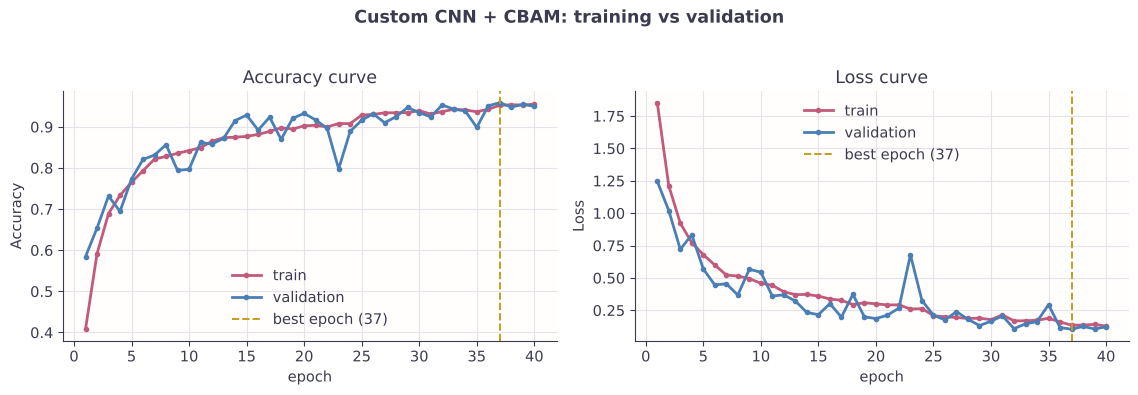

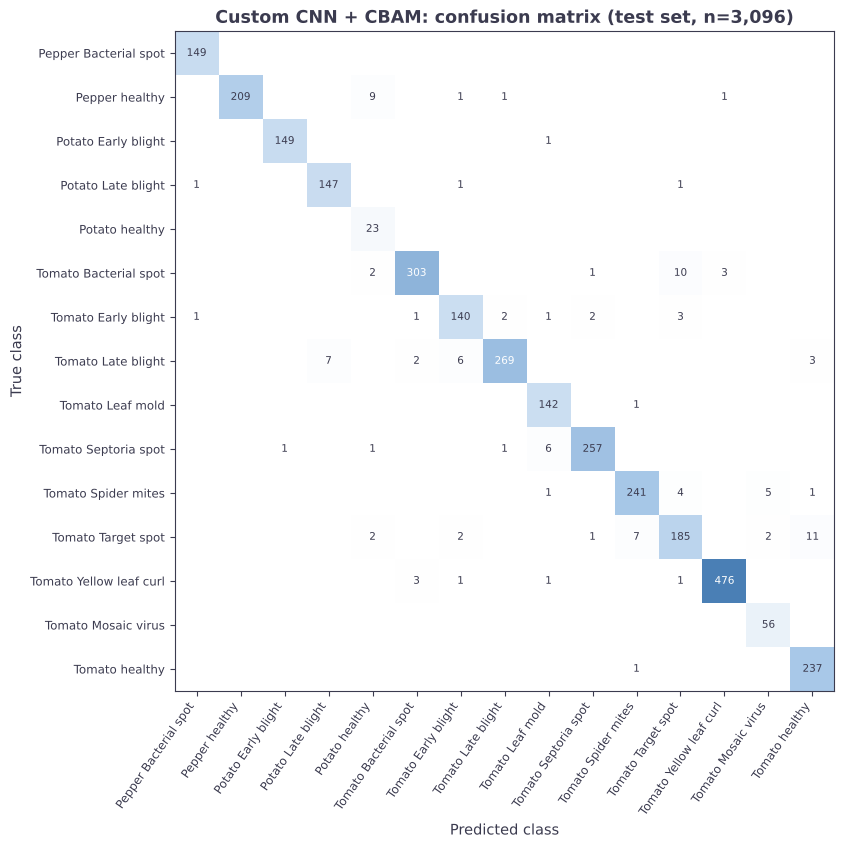

In [8]:
att = train_custom("Custom CNN + CBAM", CBAM_FACTORY, seed=SEED, fname="s4_cbam_seed42.pkl")
report_experiment(att)

---
## 7. Comparison: baseline vs CNN + CBAM

,Metric,Baseline CNN,CNN + CBAM,Change (CBAM - baseline)
0,Accuracy,0.9325,0.9635,0.0310
1,Precision (macro),0.8993,0.9373,0.0380
2,Recall (macro),0.9426,0.9680,0.0253
3,F1 (macro),0.9135,0.9492,0.0358
4,F1 (weighted),0.9331,0.9639,0.0308
5,Training time (min),13.8146,20.1793,6.3648
6,Epochs run,31.0000,40.0000,9.0000
7,Testing time (s),1.6410,2.5545,0.9135
8,ms / test image,0.5300,0.8251,0.2951
9,Parameters,263839.0000,265985.0000,2146.0000



Paired test on the 3,096 test images (seed 42): baseline-only correct = 33, CBAM-only correct = 129, exact McNemar p = 0.0000 -> difference is statistically significant (p < 0.05).


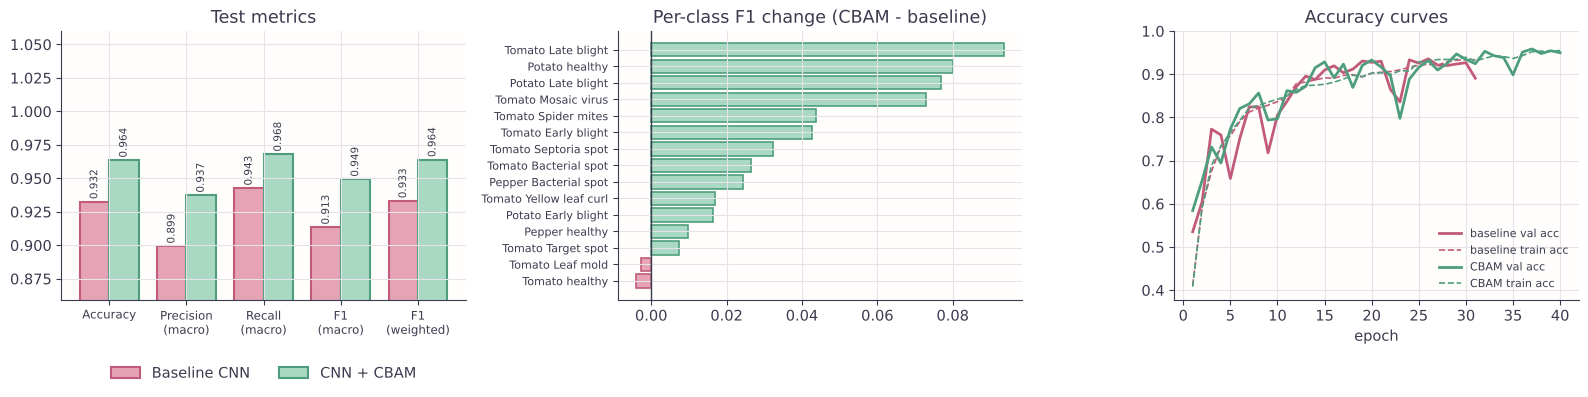


######## seed 7 ########
Baseline CNN | seed 7 | 263,839 parameters


Epoch 01/40 | train loss 1.8247 acc 0.3955 | val loss 1.1074 acc 0.6202 | lr 1.0e-03 |  30.2s  *best*


Epoch 02/40 | train loss 1.1928 acc 0.5937 | val loss 1.0661 acc 0.6050 | lr 1.0e-03 |  28.2s  *best*


Epoch 03/40 | train loss 0.9565 acc 0.6652 | val loss 0.6241 acc 0.7842 | lr 1.0e-03 |  30.0s  *best*


Epoch 04/40 | train loss 0.8246 acc 0.7145 | val loss 0.7204 acc 0.7306 | lr 1.0e-03 |  28.4s


...

Epoch 38/40 | train loss 0.1444 acc 0.9488 | val loss 0.1184 acc 0.9512 | lr 2.5e-04 |  32.9s


Epoch 39/40 | train loss 0.1478 acc 0.9458 | val loss 0.0936 acc 0.9596 | lr 2.5e-04 |  31.1s


Epoch 40/40 | train loss 0.1403 acc 0.9510 | val loss 0.0947 acc 0.9603 | lr 1.3e-04 |  31.3s


,Seed,Baseline accuracy,CBAM accuracy,Δ accuracy,Baseline F1 (macro),CBAM F1 (macro),Δ F1 (macro),Baseline epochs,CBAM epochs
0,42,0.9325,0.9635,0.0310,0.9135,0.9492,0.0358,31,40
1,7,0.9522,0.9441,-0.0081,0.9453,0.9310,-0.0144,40,31
2,2025,0.9577,0.9603,0.0026,0.9394,0.9488,0.0094,40,40


Accuracy    baseline 0.9475 ± 0.0132 | CBAM 0.9560 ± 0.0104 | mean change +0.0085
F1 (macro)  baseline 0.9327 ± 0.0169 | CBAM 0.9430 ± 0.0104 | mean change +0.0103


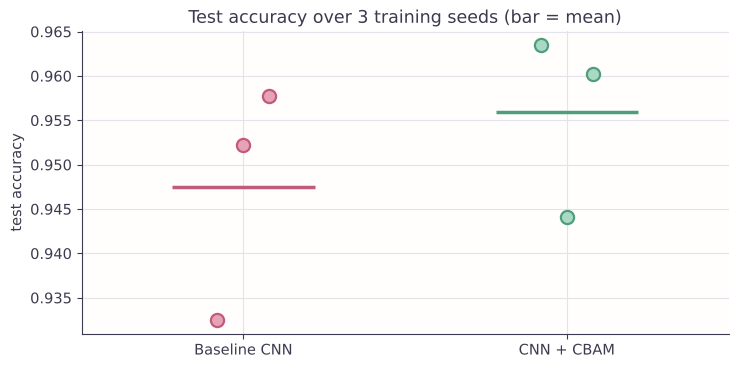

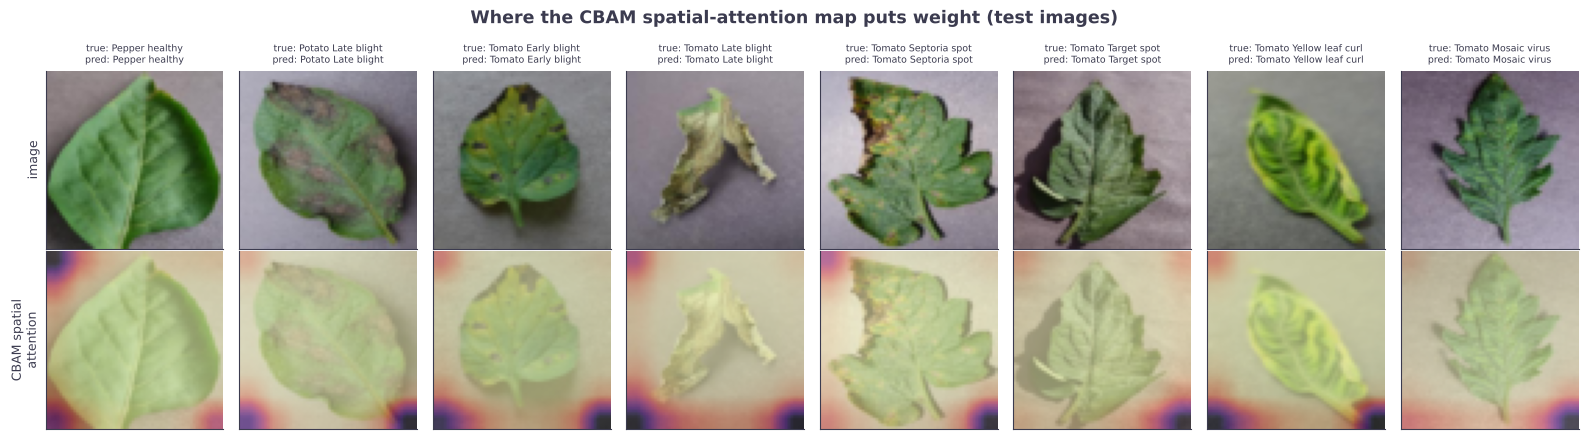

In [9]:
# ---- Baseline vs CNN + CBAM: metrics, per-class change, significance and seed study ----
from scipy.stats import binomtest

def mcnemar_exact(a, b_):
    ca, cb = a["y_pred"] == a["y_true"], b_["y_pred"] == b_["y_true"]
    only_a, only_b = int((ca & ~cb).sum()), int((~ca & cb).sum())
    p = binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    return only_a, only_b, p

KEYS = [("accuracy", "Accuracy"), ("precision_macro", "Precision (macro)"), ("recall_macro", "Recall (macro)"),
        ("f1_macro", "F1 (macro)"), ("f1_weighted", "F1 (weighted)")]
cmp_df = pd.DataFrame({"Metric": [n for _, n in KEYS] + ["Training time (min)", "Epochs run", "Testing time (s)", "ms / test image", "Parameters"]})
for tag, r in [("Baseline CNN", base), ("CNN + CBAM", att)]:
    cmp_df[tag] = [r["metrics"][k] for k, _ in KEYS] + [r["train_sec"] / 60, r["epochs_run"], r["test_sec"],
                                                          1000 * r["test_sec"] / r["n_test"], r["params_total"]]
cmp_df["Change (CBAM - baseline)"] = cmp_df["CNN + CBAM"] - cmp_df["Baseline CNN"]
display(cmp_df.round(4))
cmp_df.to_csv(RESULT_DIR / "submission4_comparison_seed42.csv", index=False)

only_b, only_a, p = mcnemar_exact(base, att)
print(f"\nPaired test on the {att['n_test']:,} test images (seed {SEED}): baseline-only correct = {only_b}, CBAM-only correct = {only_a}, "
      f"exact McNemar p = {p:.4f} -> " + ("difference is statistically significant (p < 0.05)." if p < 0.05 else "difference is NOT statistically significant (p >= 0.05)."))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(len(KEYS)); w = 0.38
for k, (tag, r, c, dc) in enumerate([("Baseline CNN", base, PAL["rose"], PAL["rose_d"]), ("CNN + CBAM", att, PAL["mint"], PAL["mint_d"])]):
    vals = [r["metrics"][key] for key, _ in KEYS]
    bars = ax[0].bar(x + (k - 0.5) * w, vals, w, color=c, edgecolor=dc, linewidth=1.5, label=tag)
    for bx, v in zip(bars, vals): ax[0].text(bx.get_x() + bx.get_width() / 2, v + 0.002, f"{v:.3f}", ha="center", fontsize=7.5, rotation=90, va="bottom")
ax[0].set_xticks(x); ax[0].set_xticklabels([n.replace(" (", "\n(") for _, n in KEYS], fontsize=8.5)
ax[0].set_ylim(min(0.9, min(r["metrics"][k] for k, _ in KEYS for r in (base, att)) - 0.04), 1.06); ax[0].set_title("Test metrics")
ax[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
delta = att["per_class_f1"] - base["per_class_f1"]; order = np.argsort(delta)
ax[1].barh(np.array(LABELS)[order], delta[order], color=[PAL["mint"] if d >= 0 else PAL["rose"] for d in delta[order]],
           edgecolor=[PAL["mint_d"] if d >= 0 else PAL["rose_d"] for d in delta[order]], linewidth=1.2)
ax[1].axvline(0, color=PAL["ink"], lw=1); ax[1].set_title("Per-class F1 change (CBAM - baseline)"); ax[1].tick_params(axis="y", labelsize=8)
for tag, r, dc in [("baseline", base, PAL["rose_d"]), ("CBAM", att, PAL["mint_d"])]:
    ax[2].plot(range(1, r["epochs_run"] + 1), r["hist"]["val_acc"], color=dc, lw=2, label=f"{tag} val acc")
    ax[2].plot(range(1, r["epochs_run"] + 1), r["hist"]["train_acc"], color=dc, lw=1.2, ls="--", label=f"{tag} train acc")
ax[2].set_xlabel("epoch"); ax[2].set_title("Accuracy curves"); ax[2].legend(frameon=False, fontsize=8); ax[2].set_ylim(max(0, min(min(r["hist"]["val_acc"] + r["hist"]["train_acc"]) for r in (base, att)) - 0.03), 1.0)
plt.tight_layout(); plt.show()

# ---- Seed study: is the gap bigger than run-to-run noise? ----
SEEDS = [42, 7, 2025]
runs = {("Baseline CNN", 42): base, ("CNN + CBAM", 42): att}
for sd in SEEDS[1:]:
    print(f"\n######## seed {sd} ########")
    runs[("Baseline CNN", sd)] = train_custom(f"Baseline CNN", None, seed=sd, fname=f"s4_baseline_seed{sd}.pkl")
    runs[("CNN + CBAM", sd)] = train_custom(f"CNN + CBAM", CBAM_FACTORY, seed=sd, fname=f"s4_cbam_seed{sd}.pkl")
seed_rows = []
for sd in SEEDS:
    b_, a_ = runs[("Baseline CNN", sd)], runs[("CNN + CBAM", sd)]
    seed_rows.append({"Seed": sd, "Baseline accuracy": b_["metrics"]["accuracy"], "CBAM accuracy": a_["metrics"]["accuracy"],
                      "Δ accuracy": a_["metrics"]["accuracy"] - b_["metrics"]["accuracy"],
                      "Baseline F1 (macro)": b_["metrics"]["f1_macro"], "CBAM F1 (macro)": a_["metrics"]["f1_macro"],
                      "Δ F1 (macro)": a_["metrics"]["f1_macro"] - b_["metrics"]["f1_macro"],
                      "Baseline epochs": b_["epochs_run"], "CBAM epochs": a_["epochs_run"]})
seed_df = pd.DataFrame(seed_rows)
display(seed_df.round(4))
for lab, col_b, col_a in [("Accuracy", "Baseline accuracy", "CBAM accuracy"), ("F1 (macro)", "Baseline F1 (macro)", "CBAM F1 (macro)")]:
    print(f"{lab:11s} baseline {seed_df[col_b].mean():.4f} ± {seed_df[col_b].std(ddof=1):.4f} | "
          f"CBAM {seed_df[col_a].mean():.4f} ± {seed_df[col_a].std(ddof=1):.4f} | mean change {(seed_df[col_a] - seed_df[col_b]).mean():+.4f}")
seed_df.to_csv(RESULT_DIR / "submission4_seed_study.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for k, (tag, dc, c) in enumerate([("Baseline CNN", PAL["rose_d"], PAL["rose"]), ("CNN + CBAM", PAL["mint_d"], PAL["mint"])]):
    vals = [runs[(tag, sd)]["metrics"]["accuracy"] for sd in SEEDS]
    ax.scatter(np.full(len(SEEDS), k) + np.linspace(-0.08, 0.08, len(SEEDS)), vals, s=90, color=c, edgecolor=dc, linewidth=1.6, zorder=3)
    ax.hlines(np.mean(vals), k - 0.22, k + 0.22, color=dc, lw=2.5, zorder=2)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Baseline CNN", "CNN + CBAM"]); ax.set_ylabel("test accuracy"); ax.set_xlim(-0.5, 1.5)
ax.set_title("Test accuracy over 3 training seeds (bar = mean)"); plt.tight_layout(); plt.show()

# ---- What does the spatial attention look at? ----
att_model = CustomCNN(attention_factory=CBAM_FACTORY).to(DEVICE); att_model.load_state_dict(att["state"]); att_model.eval()
rng = np.random.default_rng(0); pick = [int(rng.choice(np.where(y_te.numpy() == c)[0])) for c in (1, 3, 6, 7, 9, 11, 12, 13)]
fig, axes = plt.subplots(2, len(pick), figsize=(2.0 * len(pick), 4.5))
for j, i in enumerate(pick):
    xb = X_te[i:i + 1].to(DEVICE)
    with torch.no_grad(): pred = int(att_model(prep_eval(xb)).argmax(1))
    amap = F.interpolate(att_model.attention.last_spatial, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
    axes[0, j].imshow(xb[0].permute(1, 2, 0).cpu().numpy()); axes[0, j].set_title(f"true: {LABELS[int(y_te[i])]}\npred: {LABELS[pred]}", fontsize=6.8)
    axes[1, j].imshow(xb[0].permute(1, 2, 0).cpu().numpy()); axes[1, j].imshow(amap, cmap="magma", alpha=0.55)
    for a in axes[:, j]: a.set_xticks([]); a.set_yticks([]); a.grid(False)
axes[0, 0].set_ylabel("image", fontsize=9); axes[1, 0].set_ylabel("CBAM spatial\nattention", fontsize=9)
plt.suptitle("Where the CBAM spatial-attention map puts weight (test images)", fontweight="bold"); plt.tight_layout(); plt.show()

In [2]:
# ---- Paired t-test across the three training seeds: is the average gain bigger than seed-to-seed noise? ----
from scipy import stats
for name, col in [("accuracy", "Δ accuracy"), ("macro-F1", "Δ F1 (macro)")]:
    d = seed_df[col].values
    t, p = stats.ttest_1samp(d, 0.0)
    print(f"Δ {name}: mean {d.mean():+.4f} | sd {d.std(ddof=1):.4f} | CBAM better in {(d > 0).sum()} of {len(d)} seeds | paired t = {t:.2f}, p = {p:.3f}")
print("\nWith only 3 seeds this test has little power: read it as 'the average gain cannot be told apart from seed noise', not as proof that there is no effect.")

Δ accuracy: mean +0.0085 | sd 0.0202 | CBAM better in 2 of 3 seeds | paired t = 0.73, p = 0.542
Δ macro-F1: mean +0.0103 | sd 0.0251 | CBAM better in 2 of 3 seeds | paired t = 0.71, p = 0.552

With only 3 seeds this test has little power: read it as 'the average gain cannot be told apart from seed noise', not as proof that there is no effect.


In [3]:
# ---- Per-class F1 change averaged over the three seeds (a more robust view than seed 42 alone) ----
deltas = np.array([runs[("CNN + CBAM", s)]["per_class_f1"] - runs[("Baseline CNN", s)]["per_class_f1"] for s in SEEDS])
per_class = pd.DataFrame({"Class": LABELS, "Mean ΔF1 (CBAM - baseline)": deltas.mean(axis=0),
                          "Seeds where CBAM is better": (deltas > 0).sum(axis=0), "Seed 42 ΔF1": deltas[0]})
display(per_class.sort_values("Mean ΔF1 (CBAM - baseline)", ascending=False).round(4).reset_index(drop=True))

,Class,Mean ΔF1 (CBAM - baseline),Seeds where CBAM is better,Seed 42 ΔF1
0,Tomato Mosaic virus,0.0505,3,0.0730
1,Tomato Spider mites,0.0200,3,0.0437
2,Potato healthy,0.0169,2,0.0801
3,Tomato Late blight,0.0144,1,0.0935
4,Tomato healthy,0.0081,2,-0.0040
5,Tomato Yellow leaf curl,0.0074,3,0.0168
6,Tomato Septoria spot,0.0063,2,0.0324
7,Tomato Leaf mold,0.0057,2,-0.0028
8,Tomato Bacterial spot,0.0056,1,0.0264
9,Pepper Bacterial spot,0.0051,2,0.0245


### 8. Analysis: does attention help?

**What was changed.** One CBAM block (channel attention then 7×7 spatial attention, reduction 16) after the last convolution stage: +2,146 parameters (+0.81 %, 265,985 vs 263,839). Initial weights, batch order, augmentation and training recipe are identical to Submission 3.

**Seed 42 (the run shared with Submission 3).** CBAM improved test accuracy from 0.9325 to **0.9635** and macro-F1 from 0.9135 to **0.9492**. An exact McNemar test on the same 3,096 test images gives p < 0.0001 (129 images only CBAM got right, 33 only the baseline got right). It also trained longer (40 vs 31 epochs, 20.2 vs 13.8 min). This test only compares these two particular trained models; it does not show that CBAM is better in general.

**Three-seed check (42, 7, 2025).** Because one run can be lucky or unlucky, the pair was repeated with two more seeds:

| | Baseline | CBAM |
|---|---|---|
| Mean test accuracy ± sd | 0.9475 ± 0.0132 | 0.9560 ± 0.0104 |
| Mean macro-F1 ± sd | 0.9327 ± 0.0169 | 0.9430 ± 0.0104 |

The accuracy change per seed was +0.031 (seed 42), −0.008 (seed 7) and +0.003 (seed 2025): CBAM won 2 of 3 seeds. The mean gain (+0.85 points accuracy, +1.0 points macro-F1) is smaller than the seed-to-seed spread, and the paired t-test above is not significant (p ≈ 0.54). The seed-42 baseline was also its weakest run (0.9325 vs 0.952 and 0.958 for the other seeds), which is why seed 42 alone looked so impressive.

**Conclusion.** CBAM gives a **small, inconsistent improvement that we cannot separate from random variation** with three seeds. Averaged over seeds, the classes that gained most were Tomato Mosaic virus (+0.05 F1), Tomato Spider mites (+0.02) and Potato healthy (+0.02), but the per-class gains are also within noise. A real effect of the size seen is possible but not demonstrated; more seeds or a larger input size would be needed.

**What the attention maps show.** The spatial-attention maps are high over most of the leaf and low at the image corners (background). They do not single out individual lesions, so they should be read as "the model ignores the background", not as a disease localisation. The map comes from a 4×4 feature grid at 64×64 input, which is coarse.

**Cost.** +0.81 % parameters and longer training (largely because the runs differed in epoch count). Inference-time overhead cannot be resolved here: repeated timings of the same model varied from 1.6 to 3.5 s.

**Limits.** 3 seeds only, 64×64 input, CPU training, and PlantVillage near-duplicates may inflate every accuracy figure.

---
## Submission checklist
* [x] One attention module (CBAM) added to the Submission 3 CNN; everything else unchanged and verified (identical initial weights, split, augmentation, hyperparameters, seed)
* [x] Accuracy, precision, recall, F1, confusion matrix, training and testing time for the attention model
* [x] Baseline vs attention comparison table, per-class F1 change, learning curves
* [x] Paired significance test and a three-seed study to judge whether the difference is larger than run-to-run noise
* [x] CBAM spatial-attention maps on test images

All cells were run top to bottom before saving, so every table and plot is visible in this notebook.